## Failure modes and visuals

To define a blind spot in a less arbitrary way,  "near-null" will be defined as instances where the observed power does not exceed the 95% Wilson upper limit of its corresponding "clean-null." Then employ descriptive bands (low, moderate, high, and saturated). 

In [1]:
from pathlib import Path
import numpy as np,pandas as pd
import matplotlib.pyplot as plt

ROOT=Path("..")
A=ROOT/"results"/"week12"/"confirmatory"/"analysis"
MODEL=A/"formal_model"
OUT=A/"failure_modes"
OUT.mkdir(exist_ok=True)

d=pd.read_csv(MODEL/"primary_model_dataset.csv")
null_new=pd.read_csv(A/"type1_wilson.csv")

SCENARIOS=["Broken Timing","Entity Inconsistency",
"Missing Cross-Channel Reference","Over-Polished Language","Template Repetition"]
TESTS=["C2ST-Linear","C2ST-RBF","Energy","MMD","Sinkhorn"]
SEV=[.1,.3,.6]

REP={
"Broken Timing":"Broken Timing Structural",
"Entity Inconsistency":"Campaign MiniLM",
"Missing Cross-Channel Reference":"Campaign MiniLM",
"Over-Polished Language":"Message MiniLM",
"Template Repetition":"Template TF-IDF"
}

d["representation"]=d.scenario.map(REP)
print(d.shape)

(185, 9)


In [2]:
# historial N=100 null calibration
hist={
"Broken Timing Structural":[.035,.040,.065,.055,.045],
"Campaign MiniLM":[.035,.025,.055,.055,.065],
"Message MiniLM":[.050,.045,.045,.050,.050],
"Template TF-IDF":[.030,.025,.045,.045,.045]
}

rows=[]
for r,v in hist.items():
    for t,p in zip(TESTS,v):
        rows.append({"representation":r,"N":100,"test":t,
                     "rejections":round(p*200),"n_reps":200,
                     "type_I_error":p})

null100=pd.DataFrame(rows)
null100

,representation,N,test,rejections,n_reps,type_I_error
0,Broken Timing Structural,100,C2ST-Linear,7,200,0.035
1,Broken Timing Structural,100,C2ST-RBF,8,200,0.040
2,Broken Timing Structural,100,Energy,13,200,0.065
3,Broken Timing Structural,100,MMD,11,200,0.055
4,Broken Timing Structural,100,Sinkhorn,9,200,0.045
5,Campaign MiniLM,100,C2ST-Linear,7,200,0.035
6,Campaign MiniLM,100,C2ST-RBF,5,200,0.025
7,Campaign MiniLM,100,Energy,11,200,0.055
8,Campaign MiniLM,100,MMD,11,200,0.055
9,Campaign MiniLM,100,Sinkhorn,13,200,0.065


In [3]:
# Wilson Confidence Intervals for historical nulls
def wilson(k,n,z=1.959963984540054):
    p=k/n; z2=z*z; den=1+z2/n
    c=(p+z2/(2*n))/den
    h=z*np.sqrt(p*(1-p)/n+z2/(4*n*n))/den
    return c-h,c+h

ci=null100.apply(lambda x:wilson(x.rejections,x.n_reps),axis=1)
null100["wilson_low"]=[x[0] for x in ci]
null100["wilson_high"]=[x[1] for x in ci]

null_all=pd.concat([
    null_new[["representation","N","test","type_I_error","wilson_low","wilson_high"]],
    null100[["representation","N","test","type_I_error","wilson_low","wilson_high"]]
],ignore_index=True)

assert len(null_all)==60

In [4]:
# attach matched null to every power cell
d=d.merge(
    null_all,
    on=["representation","N","test"],
    how="left",
    validate="many_to_one"
)

assert d.wilson_high.notna().all()
assert len(d)==185

d.head()

,scenario,severity,N,test,rejections,n_reps,power,source,representation,type_I_error,wilson_low,wilson_high
0,Broken Timing,0.1,50,Energy,77,200,0.385,confirmatory_n50_n200,Broken Timing Structural,0.050,0.027383,0.089578
1,Broken Timing,0.1,50,MMD,75,200,0.375,confirmatory_n50_n200,Broken Timing Structural,0.055,0.030985,0.095787
2,Broken Timing,0.1,50,Sinkhorn,10,200,0.050,confirmatory_n50_n200,Broken Timing Structural,0.035,0.017056,0.070471
3,Broken Timing,0.1,200,C2ST-Linear,67,200,0.335,confirmatory_n50_n200,Broken Timing Structural,0.025,0.010725,0.057178
4,Broken Timing,0.1,200,C2ST-RBF,67,200,0.335,confirmatory_n50_n200,Broken Timing Structural,0.020,0.007804,0.050287


In [5]:
# failure mode classification
d["failure_mode"]=np.select([
    d.power<=d.wilson_high,
    d.power<.50,
    d.power<.80,
    d.power<.95
],[
    "near-null",
    "low",
    "moderate",
    "high"
],default="saturated")

d.failure_mode.value_counts()

failure_mode
saturated    71
low          43
near-null    37
high         17
moderate     17
Name: count, dtype: int64

In [6]:
# extract actual blind spots 
blind=d[d.failure_mode=="near-null"][
    ["scenario","severity","N","test","power",
     "type_I_error","wilson_high","source"]
].sort_values(["scenario","severity","N","test"])

blind.to_csv(OUT/"near_null_blind_spots.csv",index=False)

print("Near-null cells:",len(blind))
blind.round(3)

Near-null cells: 37


,scenario,severity,N,test,power,type_I_error,wilson_high,source
2,Broken Timing,0.1,50,Sinkhorn,0.050,0.035,0.070,confirmatory_n50_n200
110,Broken Timing,0.1,100,C2ST-Linear,0.025,0.035,0.070,historical_n100_anchor
113,Broken Timing,0.1,100,C2ST-RBF,0.040,0.040,0.077,historical_n100_anchor
125,Entity Inconsistency,0.1,100,C2ST-Linear,0.000,0.035,0.070,historical_n100_anchor
128,Entity Inconsistency,0.1,100,C2ST-RBF,0.000,0.025,0.057,historical_n100_anchor
137,Entity Inconsistency,0.1,100,Sinkhorn,0.045,0.065,0.108,historical_n100_anchor
23,Entity Inconsistency,0.1,200,C2ST-Linear,0.000,0.050,0.090,confirmatory_n50_n200
24,Entity Inconsistency,0.1,200,C2ST-RBF,0.000,0.060,0.102,confirmatory_n50_n200
27,Entity Inconsistency,0.1,200,Sinkhorn,0.080,0.075,0.120,confirmatory_n50_n200
126,Entity Inconsistency,0.3,100,C2ST-Linear,0.025,0.035,0.070,historical_n100_anchor


In [18]:
src_counts=pd.crosstab(
    [d.source,d.test],
    d.failure_mode
).reindex(columns=["near-null","low","moderate","high","saturated"],fill_value=0)

src_counts

failure_mode                        near-null  low  moderate  high  saturated
source                 test                                                  
confirmatory_n50_n200  C2ST-Linear          7    6         0     5          4
                       C2ST-RBF             7    6         2     3          4
                       Energy               1    5         2     1         13
                       MMD                  1    5         2     1         13
                       Sinkhorn             6    7         3     1          5
historical_n100_anchor C2ST-Linear          5    4         1     2          3
                       C2ST-RBF             5    4         2     1          3
                       Energy               0    1         2     1         11
                       MMD                  0    1         2     1         11
                       Sinkhorn             5    4         1     1          4

In [19]:
pd.crosstab(
    d.scenario,
    d.test,
    values=d.failure_mode.eq("near-null"),
    aggfunc="sum"
).fillna(0).astype(int)

test,C2ST-Linear,C2ST-RBF,Energy,MMD,Sinkhorn
scenario,,,,,
Broken Timing,1,1,0,0,1
Entity Inconsistency,4,4,0,0,4
Missing Cross-Channel Reference,3,3,1,1,2
Over-Polished Language,3,3,0,0,4
Template Repetition,1,1,0,0,0


The blind spots are **heavily concentrated by test family**, rather than randomly scattered. Across the 110 confirmatory cells, `C2ST-Linear` and `C2ST-RBF` show 7 `near-null` cases each, `Sinkhorn` shows 6, whereas `Energy` and `MMD` show only 1 each. In the historical anchors, almost the exact same structure repeats: 5, 5, and 5 for `Linear`/`RBF`/`Sinkhorn`, and 0 for `Energy`/`MMD`. This makes the pattern especially compelling because it emerges consistently in both historical and new confirmatory results.

The second table illustrates *where* they fail even better. **Entity Inconsistency is the clearest case**: `C2ST-Linear`, `C2ST-RBF`, and `Sinkhorn` account for 4 near-null cells each, whereas `Energy` and `MMD` have 0. That no longer looks like an artifact of a specific severity level or sample size ($N$); it is a structured failure mode.

**Missing Cross-Channel Reference** is the only scenario where `Energy` and `MMD` hit near-null, and only once each. That corresponds to the difficult low-signal / small sample size case we previously identified. `C2ST` once again shows 3 blind spots per configuration.

**Over-Polished Language** neatly separates `Sinkhorn` from `Energy`/`MMD`: `Sinkhorn` exhibits 4 near-null cells, `C2ST` shows 3+3 (`Linear` + `RBF`), whereas `Energy`/`MMD` show 0. And **Template Repetition** serves as a very useful conceptual control: `C2ST` has only one blind spot per variant, and `Sinkhorn` has none. In other words, `C2ST` is not inherently incapable of detecting defects; it depends heavily on how the defect manifests within the representation.

Main takeaway:

> *"Near-null detection behavior was strongly structured by defect and test configuration rather than randomly distributed across the experimental grid. C2ST-Linear, C2ST-RBF, and Sinkhorn accounted for nearly all identified blind spots, whereas Energy Distance and MMD showed near-null behavior only for the lowest-severity Missing Cross-Channel condition."*

There is another particularly good observation: `Linear` and `RBF` share the exact same total number of blind spots:

```text
C2ST-Linear   12
C2ST-RBF      12
Energy         1
MMD            1
Sinkhorn      11


This strengthens the previous conclusion: classifier linearity alone does not explain C2ST blind spots.

Since the composition of observed cells varies with $N$. These numbers are descriptive failure-mode counts, not as an inferential comparison of failure rates. 

In [7]:
# full failure mode table 
fm=d[
    ["scenario","severity","N","test","power",
     "type_I_error","wilson_high","failure_mode","source"]
].sort_values(["scenario","severity","N","test"])

fm.to_csv(OUT/"failure_mode_table.csv",index=False)
fm

,scenario,severity,N,test,power,type_I_error,wilson_high,failure_mode,source
0,Broken Timing,0.1,50,Energy,0.385,0.050,0.089578,low,confirmatory_n50_n200
1,Broken Timing,0.1,50,MMD,0.375,0.055,0.095787,low,confirmatory_n50_n200
2,Broken Timing,0.1,50,Sinkhorn,0.050,0.035,0.070471,near-null,confirmatory_n50_n200
110,Broken Timing,0.1,100,C2ST-Linear,0.025,0.035,0.070471,near-null,historical_n100_anchor
113,Broken Timing,0.1,100,C2ST-RBF,0.040,0.040,0.076932,near-null,historical_n100_anchor
...,...,...,...,...,...,...,...,...,...
172,Template Repetition,0.6,100,C2ST-Linear,1.000,0.030,0.063894,saturated,historical_n100_anchor
175,Template Repetition,0.6,100,C2ST-RBF,1.000,0.025,0.057178,saturated,historical_n100_anchor
178,Template Repetition,0.6,100,Energy,1.000,0.045,0.083297,saturated,historical_n100_anchor
181,Template Repetition,0.6,100,MMD,1.000,0.045,0.083297,saturated,historical_n100_anchor


In [8]:
# counts by test 
counts=pd.crosstab(d.test,d.failure_mode).reindex(TESTS)

order=["near-null","low","moderate","high","saturated"]
counts=counts.reindex(columns=order,fill_value=0)

counts

failure_mode,near-null,low,moderate,high,saturated
test,,,,,
C2ST-Linear,12,10,1,7,7
C2ST-RBF,12,10,4,4,7
Energy,1,6,4,2,24
MMD,1,6,4,2,24
Sinkhorn,11,11,4,2,9


In [9]:
# near null cells by test 
blind_summary=(
    d.assign(near_null=d.failure_mode.eq("near-null"))
    .groupby("test",as_index=False)
    .agg(
        observed_cells=("near_null","size"),
        near_null_cells=("near_null","sum")
    )
)

blind_summary["near_null_fraction"]=(
    blind_summary.near_null_cells/blind_summary.observed_cells
)

blind_summary.round(3)

,test,observed_cells,near_null_cells,near_null_fraction
0,C2ST-Linear,37,12,0.324
1,C2ST-RBF,37,12,0.324
2,Energy,37,1,0.027
3,MMD,37,1,0.027
4,Sinkhorn,37,11,0.297


### Figures

Blank cells indicate conditions not executed under the preregistered pruning rule; they do not represent zero power.

In [10]:
# heatmap helper 
rows=pd.MultiIndex.from_product(
    [SCENARIOS,SEV],names=["scenario","severity"]
)

def power_heatmap(N):
    z=(d[d.N==N]
       .pivot(index=["scenario","severity"],columns="test",values="power")
       .reindex(index=rows,columns=TESTS))

    fig,ax=plt.subplots(figsize=(9,8))
    im=ax.imshow(z.to_numpy(),aspect="auto",vmin=0,vmax=1)

    ax.set_xticks(range(len(TESTS)),TESTS,rotation=35,ha="right")
    ax.set_yticks(
        range(len(z)),
        [f"{s} | {v:.0%}" for s,v in z.index]
    )

    for i in range(len(z)):
        for j in range(len(TESTS)):
            x=z.iloc[i,j]
            ax.text(j,i,"—" if pd.isna(x) else f"{x:.2f}",
                    ha="center",va="center")

    ax.set_title(f"Empirical power — N={N}")
    fig.colorbar(im,ax=ax,label="Power")
    fig.tight_layout()
    fig.savefig(OUT/f"power_heatmap_N{N}.png",dpi=300)
    plt.show()

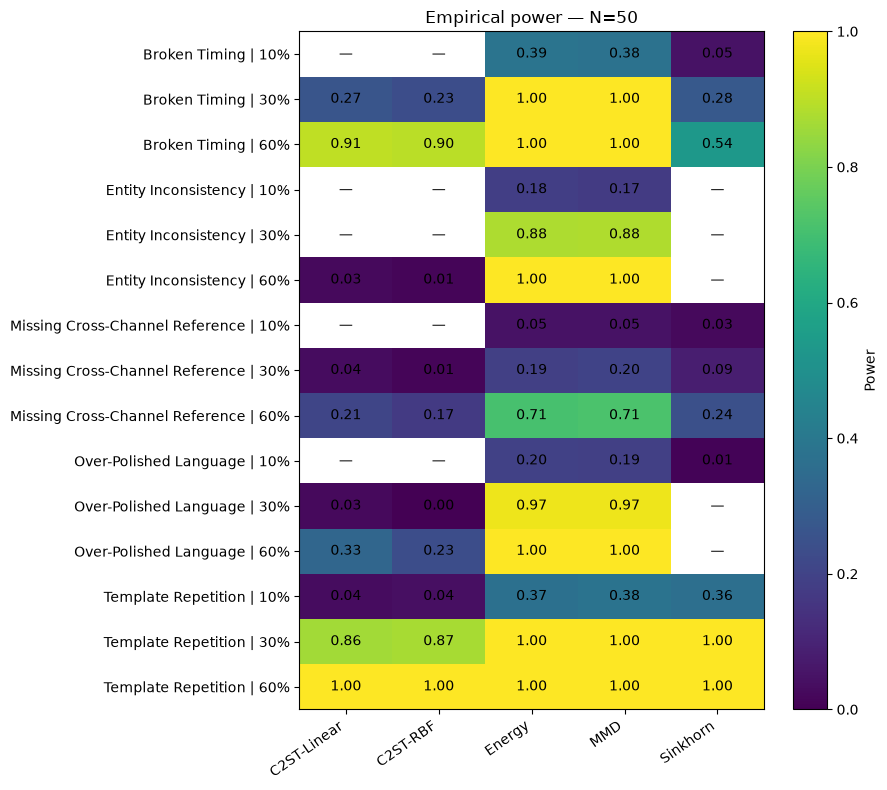

In [11]:
# heatmap n=50
power_heatmap(50)

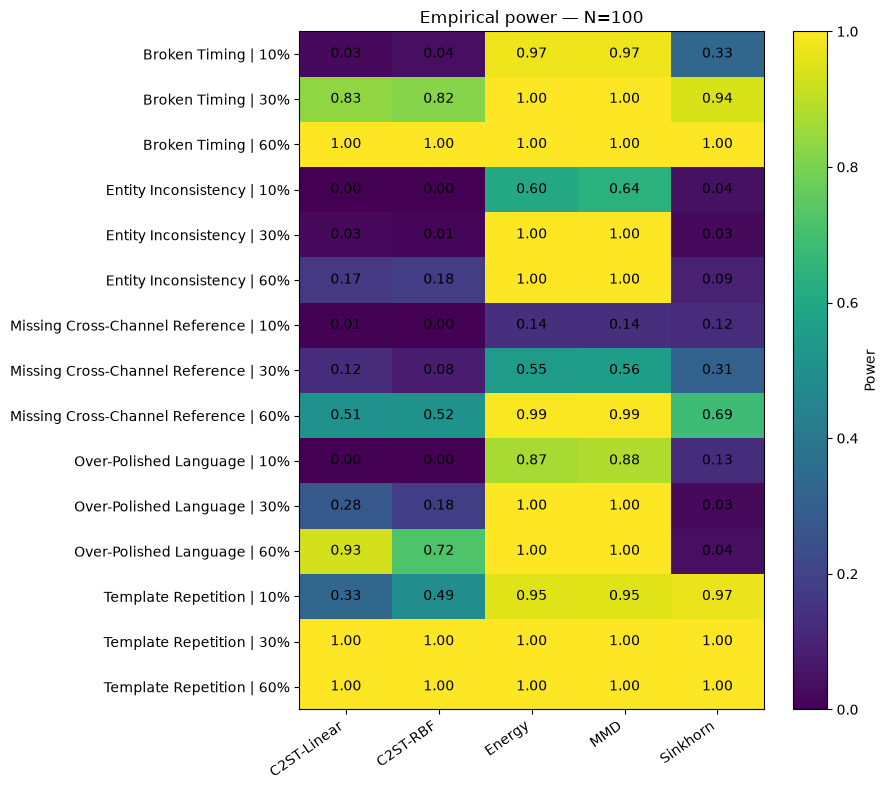

In [12]:
# n=100
power_heatmap(100)

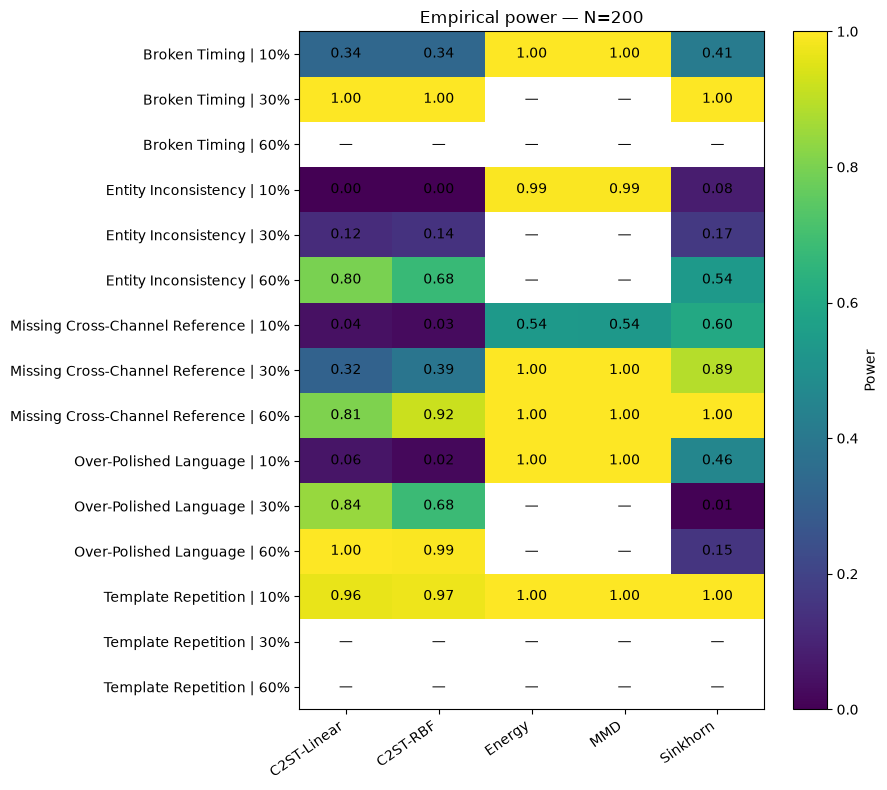

In [13]:
# heatmap n=200
power_heatmap(200)

#### Formal N × Test interaction

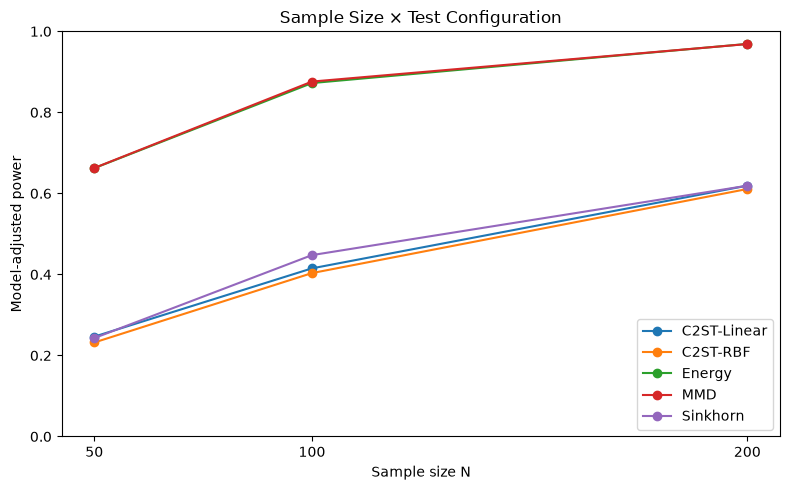

In [14]:
adj=pd.read_csv(MODEL/"adjusted_N_by_test_power.csv")

fig,ax=plt.subplots(figsize=(8,5))

for t,g in adj.groupby("test"):
    g=g.sort_values("N")
    ax.plot(g.N,g.predicted_power,marker="o",label=t)

ax.set_xticks([50,100,200])
ax.set_ylim(0,1)
ax.set_xlabel("Sample size N")
ax.set_ylabel("Model-adjusted power")
ax.set_title("Sample Size × Test Configuration")
ax.legend()
fig.tight_layout()

fig.savefig(OUT/"adjusted_N_by_test.png",dpi=300)
plt.show()

#### Severity response 
Examine how each test performs as the prevalence of the defect increases.

In [15]:
def severity_plot(scenario):
    x=d[(d.scenario==scenario)&(d.N==100)]

    fig,ax=plt.subplots(figsize=(7,5))

    for t,g in x.groupby("test"):
        g=g.sort_values("severity")
        ax.plot(g.severity,g.power,marker="o",label=t)

    ax.set_xticks(SEV,["10%","30%","60%"])
    ax.set_ylim(0,1)
    ax.set_xlabel("Defect prevalence")
    ax.set_ylabel("Power")
    ax.set_title(f"{scenario} — N=100")
    ax.legend()
    fig.tight_layout()

    name=scenario.lower().replace(" ","_").replace("-","_")
    fig.savefig(OUT/f"severity_{name}.png",dpi=300)
    plt.show()

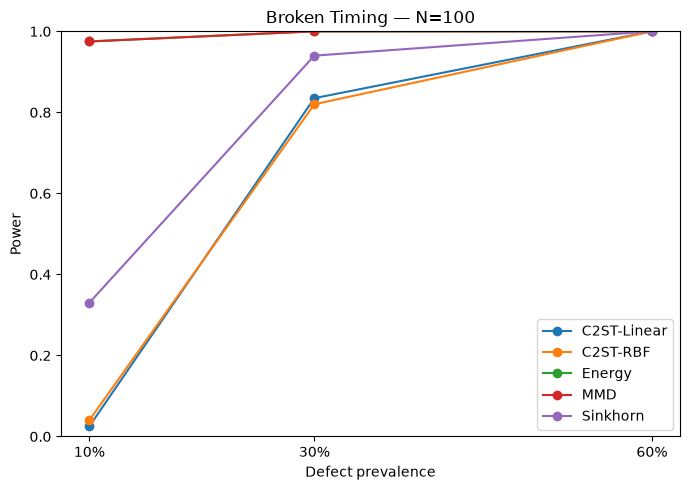

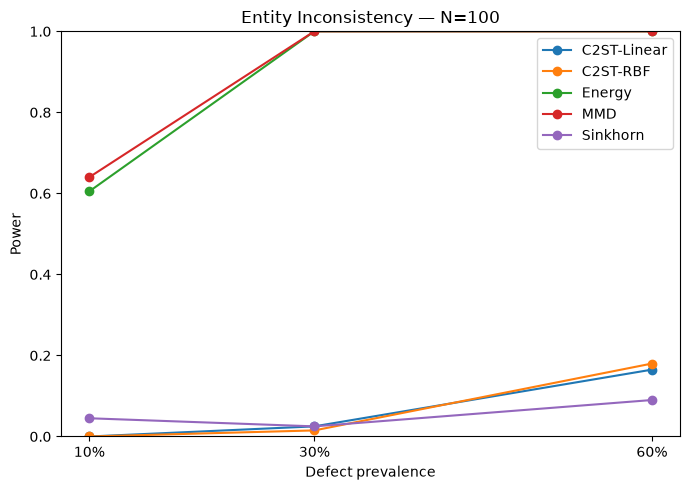

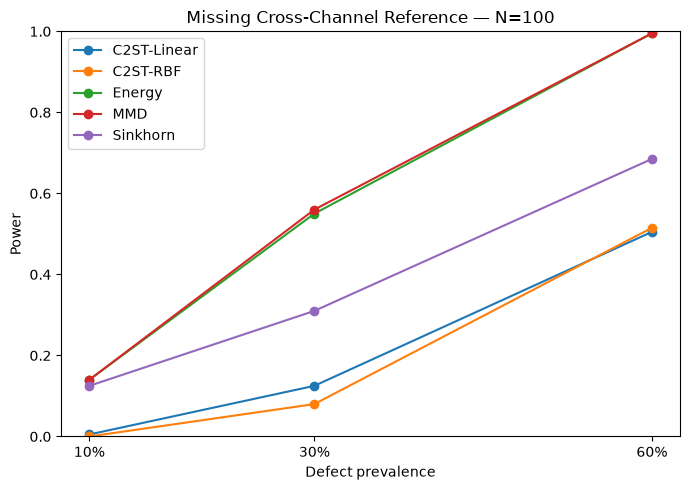

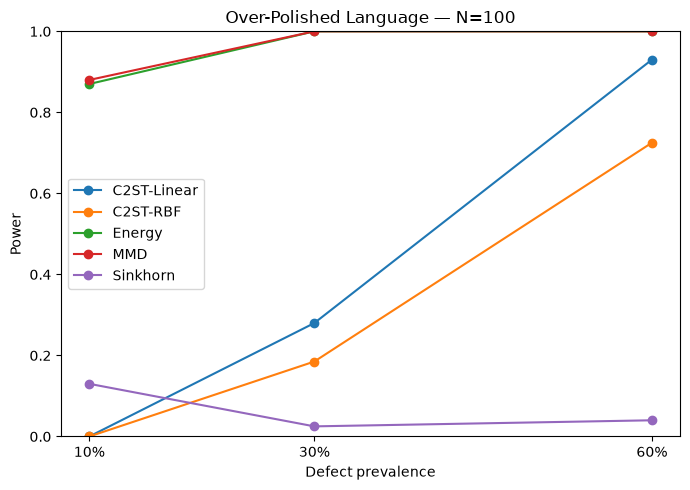

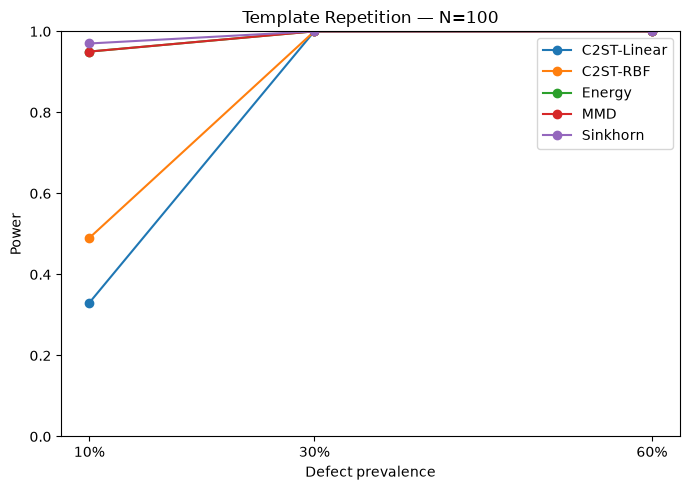

In [16]:
for s in SCENARIOS:
    severity_plot(s)

In [17]:
# save summary 
counts.to_csv(OUT/"failure_mode_counts.csv")
blind_summary.to_csv(OUT/"near_null_summary_by_test.csv",index=False)

print("Saved:")
for p in sorted(OUT.iterdir()):
    print("-",p.name)

Saved:
- adjusted_N_by_test.png
- failure_mode_counts.csv
- failure_mode_table.csv
- near_null_blind_spots.csv
- near_null_summary_by_test.csv
- power_heatmap_N100.png
- power_heatmap_N200.png
- power_heatmap_N50.png
- severity_broken_timing.png
- severity_entity_inconsistency.png
- severity_missing_cross_channel_reference.png
- severity_over_polished_language.png
- severity_template_repetition.png
